# Multiple Linear Regression

### Author
   * Jonathan Sancho Loaiza

## Problem Analysis (CRISP-DM 1: Business Understanding)

The goal is to predict the minimum temperature of a day (`MinTemp`) at Australian
weather stations from the numeric variables of the daily record.

The response variable (Y) is `MinTemp`, the minimum temperature in degrees
Celsius, and the predictor variables (X) are the numeric variables of the
dataset, namely temperatures, humidity, pressure, wind and rainfall.

Two models are built and compared. Model A is the baseline requested by the lab
brief, using every numeric variable as a predictor. Model B is a reduced model
that keeps one variable per group of redundant predictors, to deal with the
multicollinearity found during exploration.

The comparison is the point of the notebook: a model that predicts marginally
better is not automatically the better model if its coefficients cannot be
trusted.

### Libraries

In [38]:
# Dataset handling
import pandas as pd
import numpy as np

# Plots
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objs as go

# Model
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Model persistence
import copy
import os
import joblib

## Data Understanding (CRISP-DM 2)

In [39]:
# Load the data. The file is read from the notebook's own folder, and if it is
# not there the Colab sample_data folder is tried, so the notebook runs in both
import os
FILE = 'weatherAUS.csv'
path = FILE if os.path.exists(FILE) else '/content/sample_data/' + FILE
weather = pd.read_csv(path)

# First records
weather.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


Each row is one day at one Australian weather station. Beyond the numeric
measurements there are text columns (`Date`, `Location`, the wind directions and
`RainToday`) that a regression cannot take as they are, and the `NaN` values
already visible in `Evaporation` and `Sunshine` announce the missing data
problem that decides the shape of this notebook.

In [40]:
# Number of records
print("Record count:", len(weather))
# Number of columns
print("Column count:", len(weather.columns))
# Rows and columns
print("Rows and columns:", weather.shape)

Record count: 145460
Column count: 23
Rows and columns: (145460, 23)


145,460 days recorded across 23 columns. The size matters for two decisions
taken later: with this many rows every p-value ends up below 0.05, so
significance stops discriminating between models, and losing 60 % of the rows to
missing values still leaves enough data to fit a model, which is why Model A is
possible at all.

In [41]:
# Keep only the quantitative variables
numeric = weather.select_dtypes('number')
print("Numeric variables:", list(numeric.columns))

Numeric variables: ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']


The text variables (`Date`, `Location`, wind directions, `RainToday`,
`RainTomorrow`) are qualitative and are left out: a linear regression only accepts
quantitative predictors.

In [42]:
# Which columns have null values and in what proportion
missing = (numeric.isnull().mean() * 100).round(1).sort_values(ascending=False)
print(missing)

Sunshine         48.0
Evaporation      43.2
Cloud3pm         40.8
Cloud9am         38.4
Pressure9am      10.4
Pressure3pm      10.3
WindGustSpeed     7.1
Humidity3pm       3.1
Temp3pm           2.5
Rainfall          2.2
WindSpeed3pm      2.1
Humidity9am       1.8
WindSpeed9am      1.2
Temp9am           1.2
MinTemp           1.0
MaxTemp           0.9
dtype: float64


`Sunshine` is missing 48 % of its values and `Evaporation` 43 %, and both
`Cloud` variables sit around 40 %. This matters for more than data quality:
keeping them means every row lacking any of them is dropped, which costs more than
half of the dataset. The exact cost is measured below.

`MinTemp` appears in that list too, missing on 1.0 % of the records, 1,485 days.
Those days are not merely incomplete, they are unusable: with no minimum
temperature recorded there is nothing for a prediction to be compared against,
neither to train on nor to score. They leave with the rest.

### Data quality

Counting missing values says how much of the table is empty. It says nothing
about whether what is there is right. Three things are checked before the
modelling subset is built: whether any record is stored twice, whether the
values contradict each other or leave the range their unit allows, and whether
the largest values are weather or transcription errors.

In [43]:
# Structural checks that the summary statistics do not answer
print("Duplicated rows (whole record) :", weather.duplicated().sum())
print("Duplicated Date + Location     :", weather.duplicated(['Date', 'Location']).sum())

# A day cannot be colder at its maximum than at its minimum
measured = weather.dropna(subset=['MinTemp', 'MaxTemp'])
print("Days with MaxTemp below MinTemp:", (measured['MaxTemp'] < measured['MinTemp']).sum())

# Humidity is a percentage, and rainfall cannot be negative
humidity = weather[['Humidity9am', 'Humidity3pm']]
print("Humidity outside 0-100         :", int(((humidity < 0) | (humidity > 100)).sum().sum()))
print("Negative rainfall              :", int((weather['Rainfall'] < 0).sum()))

Duplicated rows (whole record) : 0
Duplicated Date + Location     : 0
Days with MaxTemp below MinTemp: 0
Humidity outside 0-100         : 0
Negative rainfall              : 0


Every check comes back clean. `Date` and `Location` identify a record uniquely
and no pair repeats, which is what makes a duplicate scan unnecessary here and
is worth confirming rather than assuming: two different days can legitimately
carry identical readings once the values are rounded, so deleting rows that look
alike would have destroyed real observations.

No day is warmer at its minimum than at its maximum, no humidity leaves the
percentage scale, and no rainfall is negative. The table is internally
consistent.

In [44]:
# How far the largest value of each variable sits from the bulk of its values
extremes = pd.DataFrame({'p99': numeric.quantile(0.99), 'max': numeric.max()})
extremes['max / p99'] = extremes['max'] / extremes['p99']
print(extremes.sort_values('max / p99', ascending=False).round(1))

                  p99     max  max / p99
Rainfall         37.4   371.0        9.9
Evaporation      18.4   145.0        7.9
WindSpeed9am     39.0   130.0        3.3
WindSpeed3pm     43.0    87.0        2.0
WindGustSpeed    81.0   135.0        1.7
MinTemp          25.8    33.9        1.3
Temp9am          31.2    40.2        1.3
Temp3pm          38.5    46.7        1.2
MaxTemp          40.1    48.1        1.2
Cloud9am          8.0     9.0        1.1
Cloud3pm          8.0     9.0        1.1
Sunshine         13.4    14.5        1.1
Humidity3pm      98.0   100.0        1.0
Pressure3pm    1031.6  1039.6        1.0
Pressure9am    1034.0  1041.0        1.0
Humidity9am     100.0   100.0        1.0


The 99th percentile is the value only one measurement in a hundred exceeds, so
comparing it against the maximum shows whether the largest reading belongs to
the same phenomenon as the rest or sits on its own. Three variables stand apart.

`Rainfall` reaches 371 mm against a 99th percentile of 37 mm. That ratio looks
alarming and is not an error: tropical cyclones do drop that much rain on the
Australian coast in a day, and rainfall is a variable where the extreme is the
event worth recording.

`Evaporation` reaches 145 mm against a 99th percentile of 18 mm, and that one
cannot be defended. Daily pan evaporation does not reach a third of that figure
anywhere, so the value is a transcription error rather than a measurement.

`Cloud9am` and `Cloud3pm` reach 9. That is not a large value, it is an
impossible one, and it is checked next.

In [45]:
# Cloud cover is reported in oktas, a scale of eighths that ends at 8
print("Cloud9am above 8:", int((weather['Cloud9am'] > 8).sum()))
print("Cloud3pm above 8:", int((weather['Cloud3pm'] > 8).sum()))

# In the synoptic code a 9 is not nine eighths of sky: it is the code for a sky
# that could not be observed, so it is not a measurement and becomes missing
weather.loc[weather['Cloud9am'] > 8, 'Cloud9am'] = np.nan
weather.loc[weather['Cloud3pm'] > 8, 'Cloud3pm'] = np.nan

# The numeric view is rebuilt so that it carries the correction
numeric = weather.select_dtypes('number')
print("\nCloud values above 8 after the correction:",
      int((numeric[['Cloud9am', 'Cloud3pm']] > 8).sum().sum()))

Cloud9am above 8: 2
Cloud3pm above 8: 1

Cloud values above 8 after the correction: 0


Three records carry a 9. Read as a quantity it would mean nine eighths of the
sky covered, which is why it cannot stay: in the synoptic code a 9 means the sky
could not be observed, usually through fog or heavy precipitation. It is a
status, not an amount, and averaging it with real okta counts would treat "not
measurable" as "more than completely overcast".

The right correction is therefore to mark it missing rather than to delete the
record or to round it down to 8. Marking it missing lets the existing
missing-value policy decide what happens to those days, instead of inventing a
cloud reading that was never taken.

`Evaporation` is treated differently, and deliberately. The okta scale has a
defined ceiling, so a 9 is wrong by definition and can be corrected without a
judgement call. Evaporation has no such ceiling: 145 mm is implausible, but any
threshold separating implausible from merely extreme would be invented here
rather than derived. It is left in the data, reported as what it is, and it
turns out to reach neither model. The recommended one does not use `Evaporation`
at all, and the day carrying the 145 mm is missing three other measurements, so
the complete-case filter applied below discards it before Model A is fitted
either. The largest evaporation any model actually sees is 81.2 mm, which the
summary table below confirms.

In [46]:
# Complete-case dataset: every numeric variable available
complete = numeric.dropna()

print("Rows with all numeric variables present:", len(complete))
print(f"Share of the original dataset: {len(complete) / len(numeric):.1%}")

Rows with all numeric variables present: 58235
Share of the original dataset: 40.0%


Keeping only the days where every numeric variable was measured leaves 58,235
rows, 40 % of the dataset. That is the price of using all the predictors the
brief asks for: three out of five days are discarded, not because they are
faulty, but because a station did not record one particular measurement.

In [47]:
# Rows available if the four variables with heavy missingness are dropped
heavy_missing = ['Sunshine', 'Evaporation', 'Cloud9am', 'Cloud3pm']
reduced_set = numeric.drop(columns=heavy_missing).dropna()

print("Rows without those four variables:", len(reduced_set))
print(f"Share of the original dataset: {len(reduced_set) / len(numeric):.1%}")

Rows without those four variables: 120381
Share of the original dataset: 82.8%


Dropping the four variables that are missing most often leaves 120,381 usable
days, 82.8 % of the dataset, against the 40 % kept before. The same data, twice
the days, at the cost of four predictors. This contrast is the second argument
for Model B, and it is independent of accuracy: it is about how many days the
model can be used on at all.

In [48]:
# Describe the dataset
complete.describe().round(2)

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,58235.00,58235.00,58235.00,58235.00,58235.00,58235.00,58235.00,58235.00,58235.00,58235.00,58235.00,58235.00,58235.00,58235.00,58235.00,58235.00
mean,13.34,24.12,2.12,5.44,7.69,40.57,15.26,19.59,66.23,49.71,1017.33,1014.88,4.25,4.33,18.08,22.62
std,6.47,6.97,6.99,3.69,3.77,13.40,8.59,8.57,18.62,20.21,6.94,6.90,2.80,2.65,6.60,6.84
min,-6.70,4.10,0.00,0.00,0.00,9.00,0.00,0.00,0.00,0.00,980.50,977.10,0.00,0.00,-0.90,3.70
25%,8.40,18.60,0.00,2.80,5.00,31.00,9.00,13.00,55.00,36.00,1012.70,1010.10,1.00,2.00,12.90,17.30
50%,13.10,23.80,0.00,4.80,8.60,39.00,15.00,19.00,67.00,51.00,1017.30,1014.80,5.00,5.00,17.70,22.30
75%,18.30,29.60,0.60,7.40,10.70,48.00,20.00,24.00,80.00,63.00,1022.00,1019.50,7.00,7.00,23.20,27.80
max,31.40,48.10,206.20,81.20,14.50,124.00,67.00,76.00,100.00,100.00,1040.40,1038.90,8.00,8.00,39.40,46.10


## Data Exploration (CRISP-DM 2) and Data Preparation (CRISP-DM 3)

In [49]:
# Correlation of each variable with MinTemp
correlations = complete.corr()['MinTemp'].drop('MinTemp')
print(correlations.sort_values(key=abs, ascending=False).round(3))

Temp9am          0.907
MaxTemp          0.750
Temp3pm          0.727
Evaporation      0.510
Pressure3pm     -0.502
Pressure9am     -0.484
Humidity9am     -0.183
WindSpeed3pm     0.149
WindSpeed9am     0.134
WindGustSpeed    0.133
Rainfall         0.115
Cloud9am         0.110
Sunshine         0.076
Humidity3pm      0.072
Cloud3pm         0.048
Name: MinTemp, dtype: float64


The same-day temperatures (`Temp9am`, `MaxTemp`, `Temp3pm`) relate most
strongly to the minimum, followed by atmospheric pressure, which relates
inversely. All three temperature correlations are positive: a warmer day goes
with a warmer night. Keep this in mind, because it will be contradicted later
by one of the models.

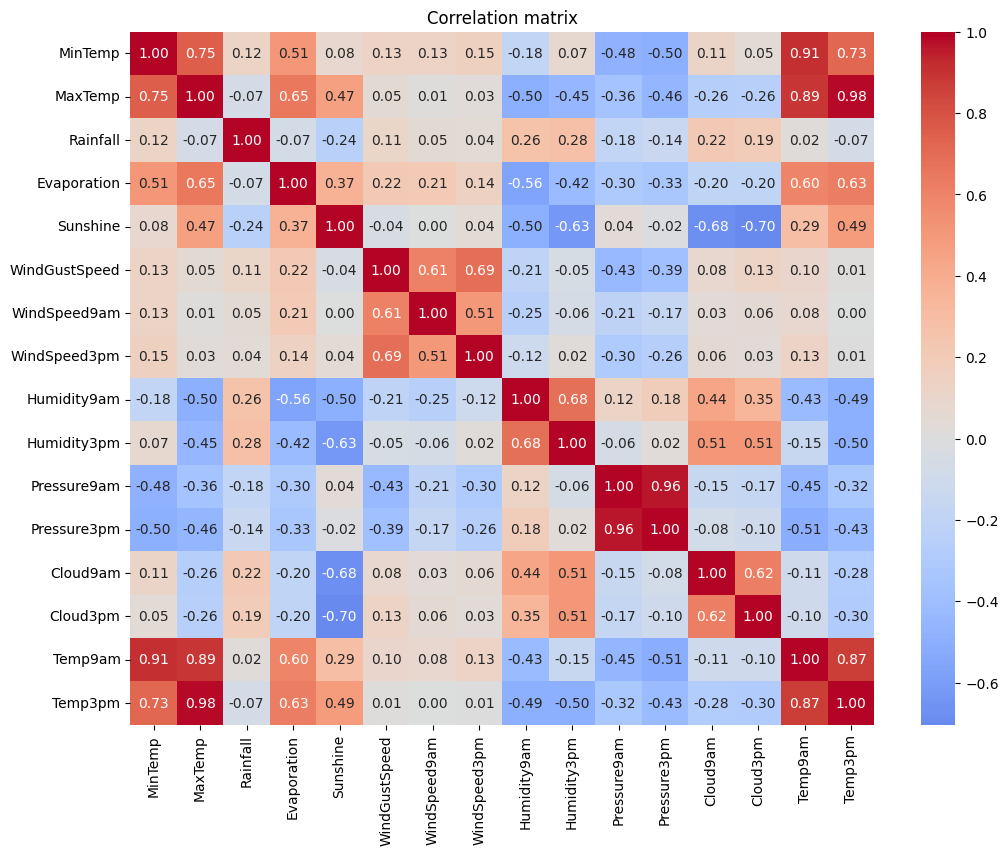

In [50]:
# Correlation matrix
corr_matrix = complete.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=True, fmt='.2f', center=0)
plt.title('Correlation matrix')
plt.show()

Each square of the heatmap holds the correlation between the variable of its row
and the one of its column, from -1 to +1, and the diagonal is always 1 because a
variable correlates perfectly with itself. The `MinTemp` row is the one that
says which predictors are useful, but the interesting part for this notebook is
elsewhere: the squares where two predictors correlate strongly with each other
are the first visible sign of the redundancy measured next.

In [51]:
# Detect multicollinearity between predictors, leaving the target out
predictor_corr = complete.drop(columns='MinTemp').corr()

print("Predictor pairs with absolute correlation above 0.75:")
for i in predictor_corr.columns:
    for j in predictor_corr.columns:
        if i < j and abs(predictor_corr.loc[i, j]) > 0.75:
            print(f"  {i} - {j}: {predictor_corr.loc[i, j]:.3f}")

Predictor pairs with absolute correlation above 0.75:
  MaxTemp - Temp9am: 0.893
  MaxTemp - Temp3pm: 0.985
  Pressure3pm - Pressure9am: 0.962
  Temp3pm - Temp9am: 0.871


`MinTemp` is dropped before the scan on purpose. It is the target, so a strong
correlation with it is what the model needs, not a defect. Multicollinearity is
about predictors repeating each other, so only pairs of predictors belong in
this list.

The pairs that come out form two groups. The three temperatures repeat each
other, with `MaxTemp` and `Temp3pm` at 0.985, which is the same measurement
under two names since the daily maximum usually happens in mid afternoon. The
two pressures repeat each other at 0.962, because atmospheric pressure moves
slowly over a day.

Correlation only inspects variables two at a time, and redundancy does not
have to happen in pairs: a variable can be harmless against each of the others
one by one and still be reconstructible from several of them combined. The
measure that catches that is the Variance Inflation Factor, VIF for short.

Variance inflation is the name of the damage. When predictors repeat each other
the model cannot tell whose effect is whose, so the uncertainty of the estimated
coefficients grows, their variance inflates, and the factor says by how much.

It is computed by taking one predictor, treating it as the target of its own
regression against all the remaining predictors, and reading how well they
manage to reproduce it. If they explain none of it, the factor is 1 and the
variable brings information nobody else has. If they explain 90 % of it, the
factor is 10, which is the threshold where the usual convention starts calling
it a problem. At 50 the others reproduce 98 % of the variable, so it is adding
almost nothing except confusion.

In [52]:
def vif_table(dataframe, predictors):
    """Return the VIF of each predictor inside the given dataframe."""
    matrix = sm.add_constant(dataframe[predictors])
    values = [variance_inflation_factor(matrix.values, i)
              for i in range(matrix.shape[1])]
    return pd.Series(values, index=matrix.columns).drop('const').sort_values(ascending=False)


all_predictors = [c for c in complete.columns if c != 'MinTemp']
print("Variance Inflation Factor (VIF), every numeric variable:")
print(vif_table(complete, all_predictors).round(1))

Variance Inflation Factor (VIF), every numeric variable:
Temp3pm          55.7
MaxTemp          46.7
Pressure3pm      19.8
Pressure9am      19.7
Temp9am          14.7
Humidity3pm       6.8
Humidity9am       4.0
Sunshine          3.3
WindGustSpeed     2.9
Cloud3pm          2.3
Cloud9am          2.2
Evaporation       2.2
WindSpeed3pm      2.2
WindSpeed9am      1.8
Rainfall          1.2
dtype: float64


`Temp3pm` (55.7) and `MaxTemp` (46.7) are far above the threshold of 10,
and both pressure variables sit near 20. These predictors carry almost the same
information as each other, so the model cannot tell how much of the effect belongs
to which.

### What multicollinearity does to the coefficients

The clearest way to show the damage is to fit the same variable set step by step
and watch the coefficients move.

In [53]:
y_demo = complete['MinTemp']

for group in [['Temp9am'], ['Temp9am', 'MaxTemp'], ['Temp9am', 'MaxTemp', 'Temp3pm']]:
    demo_model = sm.OLS(y_demo, sm.add_constant(complete[group])).fit()
    coefficients = {k: round(v, 3) for k, v in demo_model.params.items() if k != 'const'}
    print(f"{str(group):45s} -> {coefficients}")

['Temp9am']                                   -> {'Temp9am': 0.888}
['Temp9am', 'MaxTemp']                        -> {'Temp9am': 1.15, 'MaxTemp': -0.278}
['Temp9am', 'MaxTemp', 'Temp3pm']             -> {'Temp9am': 1.15, 'MaxTemp': -0.262, 'Temp3pm': -0.016}


`MaxTemp` correlates with `MinTemp` at +0.75, yet as soon as it shares the
model with `Temp9am` its coefficient turns negative. Read literally, the model
now claims that a hotter afternoon predicts a colder night, which is false. The
coefficient of `Temp9am` also jumps from 0.888 to 1.15 just because a redundant
variable entered.

That sign flip is the concrete cost of multicollinearity: the model still predicts
well, but its coefficients no longer describe reality and cannot be used to explain
anything.

### Predictor selection for Model B

One variable is kept per redundant group. From the temperature group (`MaxTemp`,
`Temp3pm`, `Temp9am`) the model keeps `Temp9am`, which is the one most correlated
with `MinTemp` by a wide margin: 0.907 against 0.750 and 0.727.

The pressure group does not settle itself that way, because both variables
correlate with the target almost identically, -0.502 for `Pressure3pm` against
-0.484 for `Pressure9am`. The tie is broken by measurement time instead: keeping
`Pressure9am` leaves Model B running on morning measurements only (`Temp9am`,
`Humidity9am`, `Pressure9am`), so it can be applied early in the day rather than
waiting for the afternoon readings.

To those, `Humidity9am`, `WindGustSpeed` and `Rainfall` are added: they carry
different information and are not redundant with the others.

The four variables with heavy missingness are excluded as well, which is what makes
Model B usable on twice as many rows.

In [54]:
selected = ['Temp9am', 'Humidity9am', 'Pressure9am', 'WindGustSpeed', 'Rainfall']

print("Variance Inflation Factor (VIF), selected predictors:")
print(vif_table(complete, selected).round(2))

Variance Inflation Factor (VIF), selected predictors:
Pressure9am      1.63
Temp9am          1.61
Humidity9am      1.44
WindGustSpeed    1.34
Rainfall         1.14
dtype: float64


Every VIF is below 1.7, far from the threshold of 10, so multicollinearity is
gone.

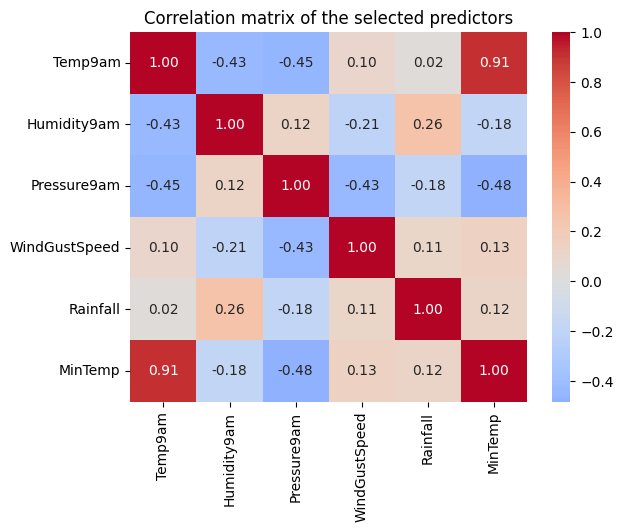

In [55]:
# Correlation matrix of the selected predictors
sns.heatmap(complete[selected + ['MinTemp']].corr(),
            cmap='coolwarm', annot=True, fmt='.2f', center=0)
plt.title('Correlation matrix of the selected predictors')
plt.show()

The same map restricted to the predictors kept for Model B. The strong colours
now sit in the `MinTemp` row and column while the squares between predictors
stay pale, which is what a set of predictors that do not repeat each other looks
like.

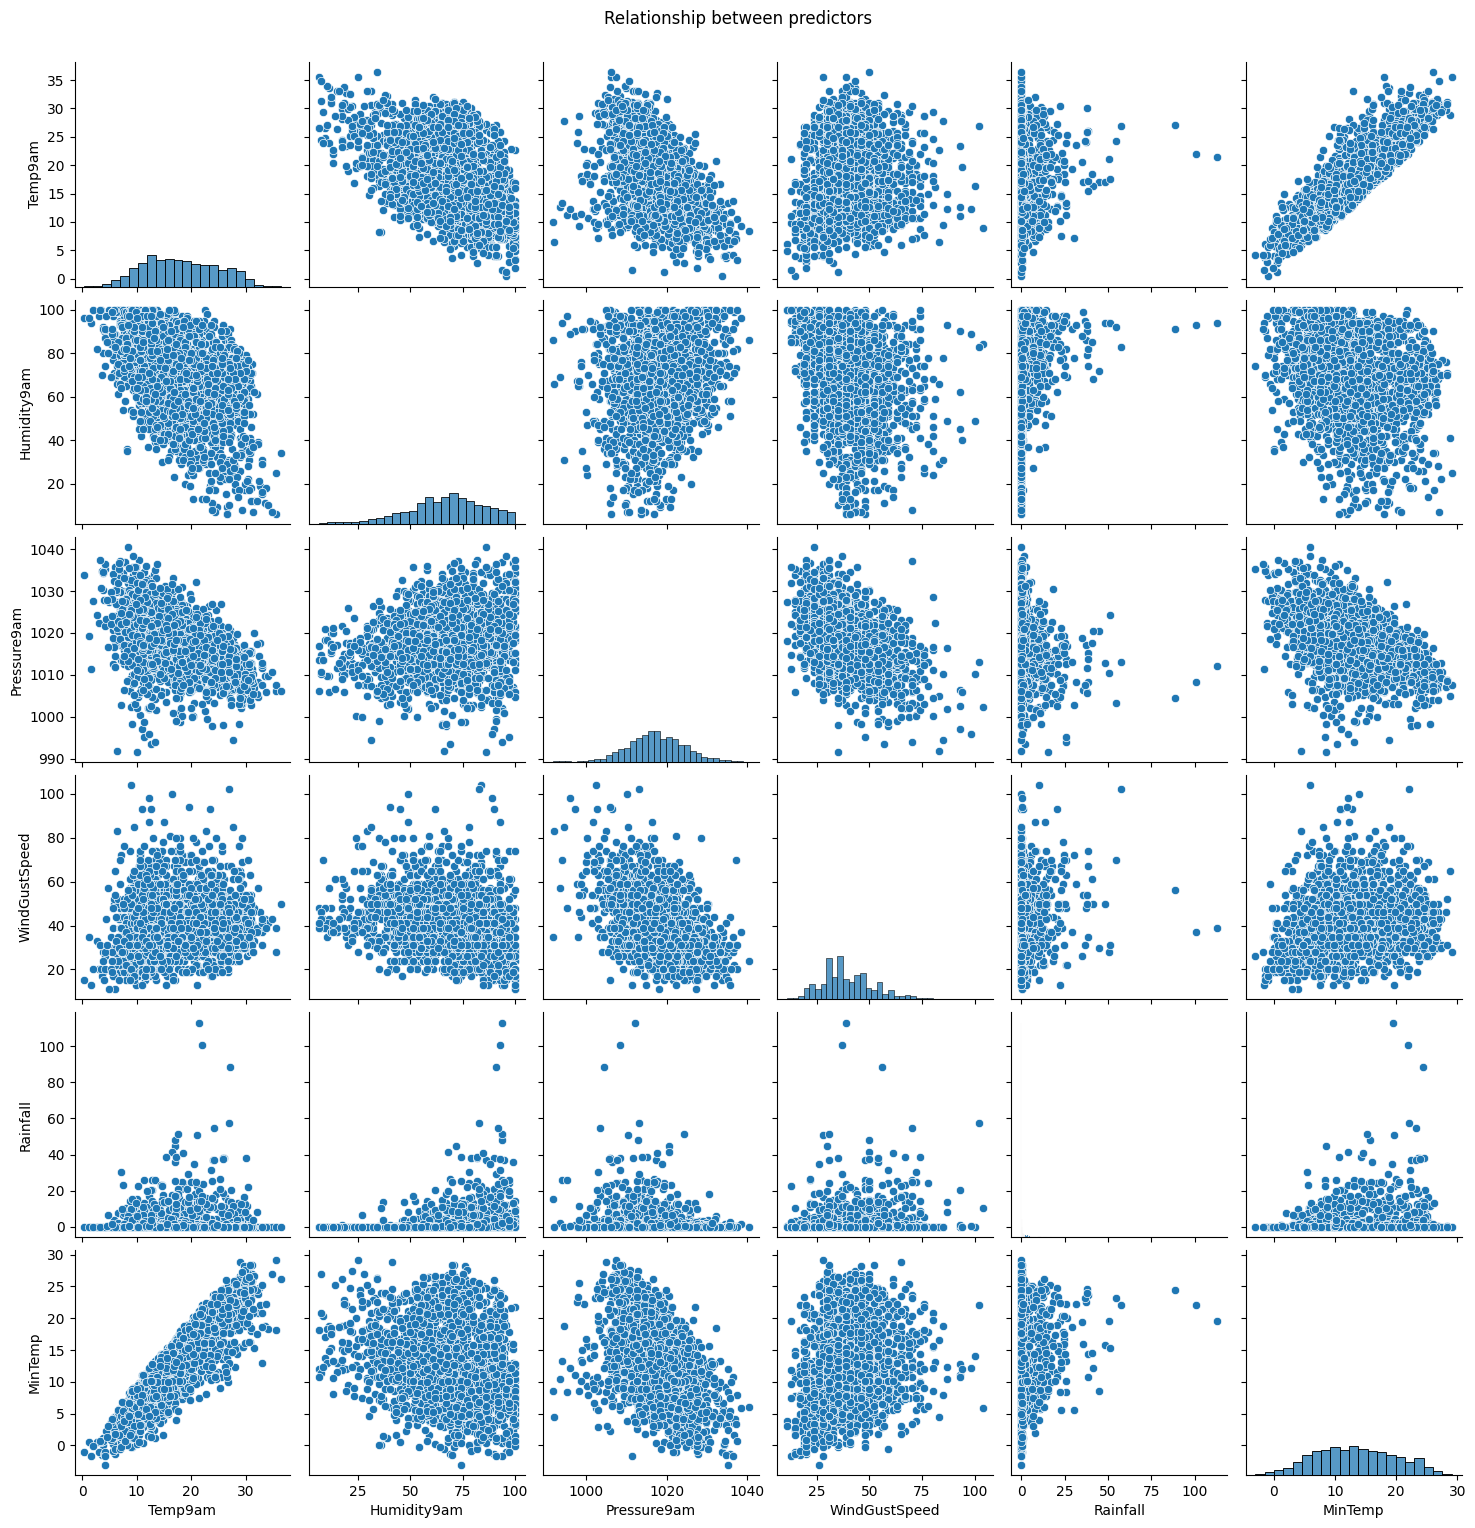

In [56]:
# Pairwise scatterplot between the selected predictors and MinTemp
sample = complete[selected + ['MinTemp']].sample(2000, random_state=42)
sns.pairplot(sample, diag_kind='hist')
plt.suptitle('Relationship between predictors', y=1.02)
plt.show()

The pairplot draws every pair of variables against each other, with the
histogram of each variable along the diagonal. It is read by rows and columns:
the `MinTemp` row shows how each predictor relates to the target, and the
remaining squares show how the predictors relate among themselves. An elongated
cloud leaning in one direction means a linear relationship and a round cloud
means none. It is drawn on a sample of 2,000 days because the 58,235 points of
the complete-case dataset would hide the shape.

In [57]:
# 3D correlation plot of the two main predictors against MinTemp
sample_3d = complete.sample(2000, random_state=42)

fig = go.Figure(data=[go.Scatter3d(
    x=sample_3d['Temp9am'],
    y=sample_3d['Humidity9am'],
    z=sample_3d['MinTemp'],
    mode='markers',
    marker=dict(size=3, color=sample_3d['MinTemp'],
                colorscale='Viridis', opacity=0.8)
)])

fig.update_layout(title='3D Scatterplot',
                  scene=dict(xaxis_title='Temp9am',
                             yaxis_title='Humidity9am',
                             zaxis_title='MinTemp'))
fig.show()

The 3D scatter shows the two strongest predictors at the same time against the
target. Every point is a day placed by its temperature at 9am, its humidity at
9am and its minimum temperature, and the colour repeats the minimum temperature
so that depth stays readable on a flat screen. The plot can be rotated with the
mouse. Two predictors that work well together look like a tilted sheet of
points, not like a shapeless ball.

## Machine Learning Model (CRISP-DM 4: Modeling)

Both models are trained on the same rows, the complete-case
dataset, so the comparison measures the effect of the predictor set alone and not
the effect of having more or less data.

In [58]:
# Split the dataset into a training set and a test set
weather_train, weather_test = train_test_split(
    complete, test_size=0.2, random_state=42)

print(".................................Training..................................")
print(weather_train[selected + ['MinTemp']].describe().round(2))
print(".................................Test......................................")
print(weather_test[selected + ['MinTemp']].describe().round(2))

.................................Training..................................
        Temp9am  Humidity9am  Pressure9am  WindGustSpeed  Rainfall   MinTemp
count  46588.00     46588.00     46588.00        46588.0  46588.00  46588.00
mean      18.07        66.22      1017.31           40.6      2.12     13.33
std        6.61        18.64         6.95           13.4      6.93      6.47
min       -0.90         0.00       980.50            9.0      0.00     -6.70
25%       12.90        55.00      1012.70           31.0      0.00      8.40
50%       17.70        67.00      1017.20           39.0      0.00     13.10
75%       23.12        80.00      1021.90           48.0      0.60     18.30
max       39.40       100.00      1040.30          124.0    183.00     31.40
.................................Test......................................
        Temp9am  Humidity9am  Pressure9am  WindGustSpeed  Rainfall   MinTemp
count  11647.00     11647.00     11647.00       11647.00  11647.00  11647.00
m

Test observations falling outside the training range are removed to avoid
extrapolation. The check runs over all fifteen numeric variables, which is
stricter than Model B alone would require, so that both models are then scored
on exactly the same rows. Two of them fall outside.

In [59]:
# Remove out-of-range data from the test set
before = len(weather_test)
in_range = pd.Series(True, index=weather_test.index)

for var in all_predictors:
    in_range &= (weather_test[var] >= weather_train[var].min()) & \
                (weather_test[var] <= weather_train[var].max())

weather_test = weather_test[in_range].copy()
print("Observations removed from the test set:", before - len(weather_test))

Observations removed from the test set: 2


### Model A: every numeric variable (the brief's baseline)

In [60]:
X_train_a = sm.add_constant(weather_train[all_predictors])
y_train = weather_train['MinTemp']

model_a = sm.OLS(y_train, X_train_a).fit()
print(model_a.summary())

                            OLS Regression Results                            
Dep. Variable:                MinTemp   R-squared:                       0.909
Model:                            OLS   Adj. R-squared:                  0.909
Method:                 Least Squares   F-statistic:                 3.112e+04
Date:                Wed, 19 Aug 2026   Prob (F-statistic):               0.00
Time:                        21:40:28   Log-Likelihood:                -97221.
No. Observations:               46588   AIC:                         1.945e+05
Df Residuals:                   46572   BIC:                         1.946e+05
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             3.6828      1.782      2.067

Model A explains 90.9 % of the variation of `MinTemp` with 15 predictors fitted
on 46,588 training days, and every predictor's `P>|t|` is 0.000, so by the usual criterion
every variable belongs in the model.

The `coef` column tells a different story. `MaxTemp` gets a coefficient of
-0.1979, meaning the model claims that a hotter afternoon goes with a colder
night, when the correlation between the two is +0.75. A coefficient whose sign
contradicts the correlation of its own variable is the readable symptom of
multicollinearity, and significance did not flag it.

In [61]:
# Predictors whose coefficient sign contradicts their correlation with MinTemp
print("Sign contradictions in Model A:")
for var in all_predictors:
    if np.sign(model_a.params[var]) != np.sign(correlations[var]):
        print(f"  {var}: correlation {correlations[var]:+.3f} "
              f"but coefficient {model_a.params[var]:+.3f}")

Sign contradictions in Model A:
  MaxTemp: correlation +0.750 but coefficient -0.198
  Rainfall: correlation +0.115 but coefficient -0.005
  Sunshine: correlation +0.076 but coefficient -0.119
  WindSpeed3pm: correlation +0.149 but coefficient -0.019
  Humidity9am: correlation -0.183 but coefficient +0.070
  Pressure3pm: correlation -0.502 but coefficient +0.168
  Cloud3pm: correlation +0.048 but coefficient -0.099


Every `P>|t|` is below 0.05, so by the usual significance criterion no
variable looks removable. Significance, however, says nothing about whether a
coefficient is interpretable, and several of them carry the wrong sign.

### Model B: selected predictors

In [62]:
X_train_b = sm.add_constant(weather_train[selected])

model_b = sm.OLS(y_train, X_train_b).fit()
print(model_b.summary())

                            OLS Regression Results                            
Dep. Variable:                MinTemp   R-squared:                       0.884
Model:                            OLS   Adj. R-squared:                  0.884
Method:                 Least Squares   F-statistic:                 7.098e+04
Date:                Wed, 19 Aug 2026   Prob (F-statistic):               0.00
Time:                        21:40:28   Log-Likelihood:            -1.0295e+05
No. Observations:               46588   AIC:                         2.059e+05
Df Residuals:                   46582   BIC:                         2.060e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            18.7237      1.951      9.599

Model B explains 88.4 % of the variation with 5 predictors instead of 15, so
dropping ten redundant variables cost 2.5 points of R2. `Temp9am` adds 0.9769
degrees to the minimum per degree measured at 9am, and `Pressure9am` subtracts
0.0299 per hectopascal, matching the inverse relationship seen in the
correlation matrix.

The sign check already run on Model A is repeated below on Model B, this time
with the VIF of each predictor beside it, because the count of contradictions is
not the part that matters: what causes them is.

In [63]:
# Same sign check as Model A, with the VIF of each predictor beside it
vif_b = vif_table(complete, selected)

print("Sign check in Model B:")
for var in selected:
    agrees = np.sign(model_b.params[var]) == np.sign(correlations[var])
    verdict = 'agrees     ' if agrees else 'CONTRADICTS'
    print(f"  {var:15s} correlation {correlations[var]:+.3f}"
          f"   coefficient {model_b.params[var]:+.4f}"
          f"   {verdict}   VIF {vif_b[var]:.2f}")

Sign check in Model B:
  Temp9am         correlation +0.907   coefficient +0.9769   agrees        VIF 1.61
  Humidity9am     correlation -0.183   coefficient +0.0900   CONTRADICTS   VIF 1.44
  Pressure9am     correlation -0.484   coefficient -0.0299   agrees        VIF 1.63
  WindGustSpeed   correlation +0.133   coefficient +0.0331   agrees        VIF 1.34
  Rainfall        correlation +0.115   coefficient +0.0157   agrees        VIF 1.14


Model B leaves one contradiction where Model A left seven, and that one is a
different kind of thing, which is why the VIF is printed next to it.

`Humidity9am` correlates -0.183 with `MinTemp` yet enters the model with a
positive coefficient, and its VIF is 1.44. With no redundancy to blame, the
coefficient is stable, and the flip is not damage: it is the difference between a
marginal correlation and a partial effect.

Taken on its own, humid mornings tend to be cool mornings, because relative
humidity falls as the air warms, so the raw correlation with `MinTemp` comes out
negative. Inside the model, `Temp9am` already accounts for how warm the morning
was, so what `Humidity9am` adds on top of it is the moisture of two mornings that
were equally warm. There the physics runs the other way: more moisture means a
higher dew point and less heat radiated away overnight, so the night does not
cool as far. The positive coefficient is the correct one.

None of that can be said about `MaxTemp` in Model A. Its flip comes with a VIF of
46.7, which means the coefficient is not measuring a partial effect at all: it is
an unstable number that moves with whichever redundant variables happen to be in
the model, exactly as the step by step demonstration showed.

So the rule is not that a sign contradiction condemns a model. It is that a
contradiction has to be explainable, and it can only be explained when the
predictor is not redundant. Model B meets that condition on all five of its
predictors; Model A meets it on none of its seven.

### The condition number in the summary

One line of Model B's summary has not been accounted for yet. Under the
coefficient table, note [2] reports a condition number of 1.95e+05 and warns that
it "might indicate that there are strong multicollinearity or other numerical
problems". The VIF table put every predictor below 1.7, so the two readings have
to be reconciled rather than left to contradict each other.

The condition number is computed on the design matrix exactly as it is handed
over, and these columns are not on comparable scales: `Pressure9am` sits around
1017 hectopascals while `Rainfall` averages about 2 millimetres. Putting every
predictor on the same scale separates the two candidate causes, because
standardizing removes the difference in units without touching the relationships
between the variables.

In [64]:
# Refit Model B with every predictor on the same scale, to find out whether the
# condition number is reporting redundancy or only the spread of the units
standardized = weather_train[selected].apply(lambda c: (c - c.mean()) / c.std())
model_b_std = sm.OLS(y_train, sm.add_constant(standardized)).fit()

print(f"Condition number, predictors as measured : {model_b.condition_number:.3e}")
print(f"Condition number, predictors standardized: {model_b_std.condition_number:.2f}")
print(f"R2 as measured  : {model_b.rsquared:.6f}")
print(f"R2 standardized : {model_b_std.rsquared:.6f}")
print("t-statistics unchanged:",
      np.allclose(model_b.tvalues[selected], model_b_std.tvalues[selected]))

Condition number, predictors as measured : 1.948e+05
Condition number, predictors standardized: 2.41
R2 as measured  : 0.883973
R2 standardized : 0.883973
t-statistics unchanged: True


Standardizing changes nothing about the model: R2 is identical to the sixth
decimal and every t-statistic is unchanged, which is expected, since rescaling a
predictor only rescales its coefficient by the same factor. What it does change
is the condition number, which drops from about 195,000 to 2.41.

A quantity that collapses when the units change was not measuring redundancy
between the predictors. It was measuring the spread of their scales. The note is
generic text that statsmodels prints whenever the condition number passes a
threshold, and it lists multicollinearity as one possible cause among others,
which is why it has to be checked rather than believed.

The VIF table is the measurement that answers the question directly, one
predictor at a time, and it puts all five below 1.7. That is the reading that
stands: Model B has no multicollinearity problem.

In [65]:
# Equation of Model B
equation = f"MinTemp = {model_b.params['const']:.3f}"
for var in selected:
    sign = '+' if model_b.params[var] >= 0 else '-'
    equation += f" {sign} {abs(model_b.params[var]):.4f}*{var}"
print(equation)

MinTemp = 18.724 + 0.9769*Temp9am + 0.0900*Humidity9am - 0.0299*Pressure9am + 0.0331*WindGustSpeed + 0.0157*Rainfall


Each coefficient is a partial effect: how much `MinTemp` changes when that
variable rises by one unit while the others are held constant. That is what lets
the equation be read as a description of the weather and not only as a
prediction device, the `Humidity9am` term included, whose sign describes what
moisture does to a night once the temperature of the morning is already
accounted for.

The intercept has no practical reading: it would be the minimum temperature with
pressure, humidity, wind and rainfall all at zero, which never happens.

## Evaluation (CRISP-DM 5)

In [66]:
def evaluate(model, predictors, label):
    """Return the test metrics of a fitted model as a dictionary."""
    predictions = model.predict(sm.add_constant(weather_test[predictors]))
    actual = weather_test['MinTemp']
    return {
        'Model': label,
        'Predictors': len(predictors),
        'Train R2': round(model.rsquared, 4),
        'Adj. R2': round(model.rsquared_adj, 4),
        'Test R2': round(r2_score(actual, predictions), 4),
        'MAE': round(mean_absolute_error(actual, predictions), 3),
        'RMSE': round(np.sqrt(mean_squared_error(actual, predictions)), 3),
    }


comparison = pd.DataFrame([
    evaluate(model_a, all_predictors, 'A - all numeric variables'),
    evaluate(model_b, selected, 'B - selected predictors'),
])
comparison

,Model,Predictors,Train R2,Adj. R2,Test R2,MAE,RMSE
0,A - all numeric variables,15,0.9093,0.9093,0.9081,1.516,1.949
1,B - selected predictors,5,0.8840,0.8840,0.8825,1.732,2.204


Model A predicts better, by about 0.026 of R² and 0.22 °C of average
error. It is a real advantage and it should not be hidden, but it is a small one,
and it comes with the cost measured next.

In [67]:
# Usable rows for each model over the full dataset
rows_a = len(numeric.dropna())
rows_b = len(numeric[selected + ['MinTemp']].dropna())

print(f"Model A usable rows: {rows_a:,} ({rows_a / len(numeric):.1%} of the dataset)")
print(f"Model B usable rows: {rows_b:,} ({rows_b / len(numeric):.1%} of the dataset)")
print(f"Model B keeps {rows_b / rows_a:.1f} times more observations")

Model A usable rows: 58,235 (40.0% of the dataset)
Model B usable rows: 121,509 (83.5% of the dataset)
Model B keeps 2.1 times more observations


Over the whole dataset Model A can be applied to 58,235 days and Model B to
121,509, which is 2.1 times more. The difference is not a modelling choice but a
data availability one: Model A needs four measurements that many stations simply
do not record, so on those days it cannot produce any prediction at all, while
Model B only needs measurements that are almost always there.

The diagnostics are run on Model B because it is the one being recommended, and
a model is validated before it is used. Model A is not left unchecked, it is
checked where its problem actually is: its residuals are not what fails, since
it is the more accurate of the two on the test set. What fails are its
coefficients, and that was measured already with the VIF and the sign check.
Running the same four plots on Model A would confirm that it fits well, which is
not in dispute.

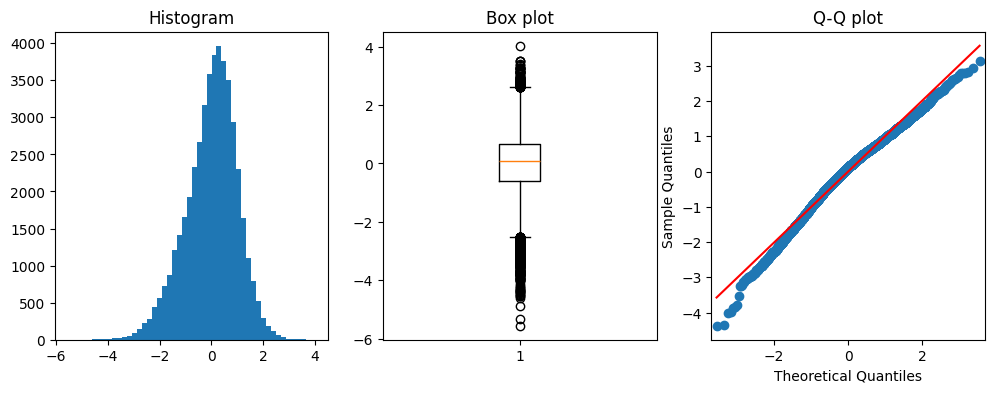

In [68]:
# Standardized residuals of the chosen model
residuals = model_b.get_influence().resid_studentized_internal

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].hist(residuals, bins=50)
ax[0].set_title('Histogram')
ax[1].boxplot(residuals)
ax[1].set_title('Box plot')
sm.qqplot(pd.Series(residuals).sample(5000, random_state=42), line='s', ax=ax[2])
ax[2].set_title('Q-Q plot')
plt.show()

The three panels look at the same residuals in three ways. The histogram shows
their shape, which should be a bell centred on zero. The box plot summarises
them in five numbers: the orange line is the median error, the box holds the
middle half of the residuals, the whiskers reach as far as the errors that still
count as ordinary, and any circle beyond them is an observation the model missed
by an unusual amount. The Q-Q plot compares the residuals against a normal
distribution, so points along the diagonal mean the normality assumption holds.

The residuals are standardized, which means the axis is measured in standard
deviations instead of the units of the target, so a residual of 2 is an error
twice as large as the typical one and values beyond 3 are rare.

With almost 50,000 residuals it is normal for the box plot to show a dense
column of circles past the whiskers: the rule that draws them uses a fixed
proportion of the box, so the more observations there are, the more points fall
outside it. What matters is that they appear on both sides in similar numbers.

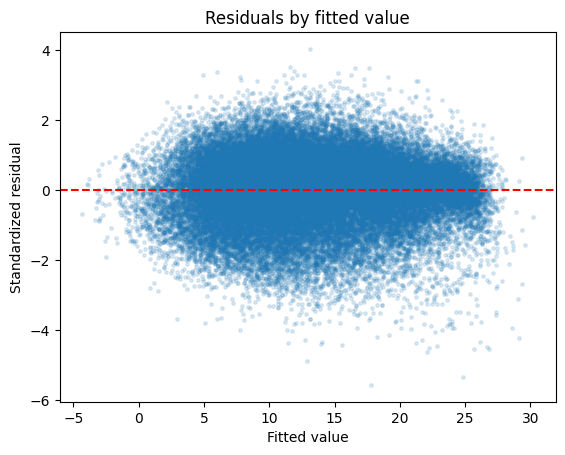

In [69]:
# Residuals against fitted values
plt.scatter(model_b.fittedvalues, residuals, alpha=0.15, s=6)
plt.axhline(0, color='red', linestyle='--')
plt.title('Residuals by fitted value')
plt.xlabel('Fitted value')
plt.ylabel('Standardized residual')
plt.show()

This plot puts every residual against the value the model predicted for that
observation, with the dashed red line at zero marking a perfect prediction. What
is being looked for here is the absence of a pattern: a shapeless cloud of the
same height along the whole axis. A cloud that widens, curves or splits into
separate groups means the size of the error depends on the prediction, which is
exactly what a linear model assumes does not happen.

The residuals are symmetric around zero with an even spread across the
fitted values: homoscedasticity holds and no systematic pattern appears, so the
conditions of the linear model are met.

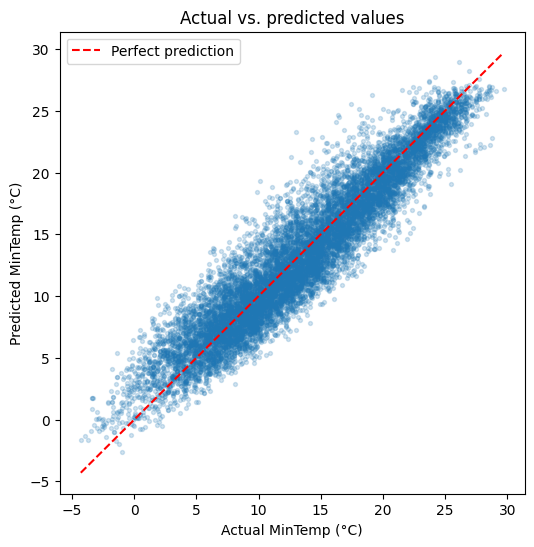

In [70]:
# Predictions of the chosen model on the test set
weather_test['Prediction'] = model_b.predict(sm.add_constant(weather_test[selected]))
weather_test['Residuals'] = weather_test['MinTemp'] - weather_test['Prediction']

plt.figure(figsize=(6, 6))
plt.scatter(weather_test['MinTemp'], weather_test['Prediction'], alpha=0.2, s=8)
limits = [weather_test['MinTemp'].min(), weather_test['MinTemp'].max()]
plt.plot(limits, limits, color='red', linestyle='--', label='Perfect prediction')
plt.title('Actual vs. predicted values')
plt.xlabel('Actual MinTemp (°C)')
plt.ylabel('Predicted MinTemp (°C)')
plt.legend()
plt.show()

Every point is a test day placed by its real minimum temperature and the one the
model predicted for it, and the dashed red line is where both coincide, so a
perfect model would leave every point on top of it. Points above the line are
days predicted warmer than they turned out and points below are days predicted
colder. The cloud stays tight around the line along the whole range, which is
what an R2 close to 0.88 looks like drawn.

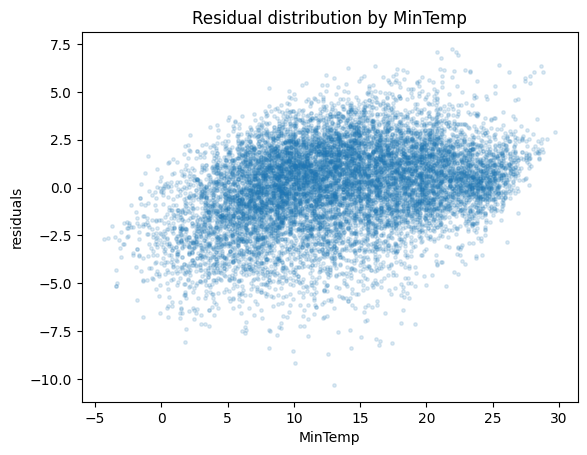

In [71]:
plt.scatter(x=weather_test['MinTemp'], y=weather_test['Residuals'], alpha=0.15, s=6)
plt.title('Residual distribution by MinTemp')
plt.xlabel('MinTemp')
plt.ylabel('residuals')
plt.show()

This last plot puts the residuals against the real minimum temperature instead
of the predicted one, and the band of points tilts upward. That tilt is expected
in any model that does not explain all the variation of the target: a day colder
than average tends to be predicted warmer than it was, and a hot day tends to be
predicted colder, so the error and the actual value move together. It is a
property of comparing the error against the actual value, not a fault of the
model, which is why the plot that decides whether the assumptions hold is the
earlier one against the fitted value.

In [72]:
# Manual prediction: a day with 15 °C at 9am, 70 % humidity,
# 1015 hPa pressure, 35 km/h wind gusts and no rainfall
print(model_b.predict([[1, 15.0, 70.0, 1015.0, 35.0, 0.0]]))

[10.51651601]


The model estimates a minimum of 10.5 degrees for that day. All five inputs fall
inside the ranges the model was trained on, so this is an interpolation and not
an extrapolation, and the figure should be read together with the average error
of 1.73 degrees measured on the test set.

### Model persistence

The recommended model is saved to disk so it can be reused without training it
again, which is what makes a fitted model usable outside the notebook. The saved
file is loaded back and asked for the same prediction, so the copy on disk is
verified to answer exactly like the model that was just fitted.

The object returned by `fit()` keeps the 46,588 training rows attached to it,
which is what the notebook needs to print a summary or recompute a statistic,
but not what a deployed model needs: to predict a new day it is enough to carry
the six coefficients. `remove_data()` strips the training data off a copy before
saving, and the printed size shows the difference that makes.

In [73]:
# The fitted object still carries the 46,588 training rows, which a deployed
# model does not need: what gets deployed is the equation, not the data
deployable = copy.deepcopy(model_b)
deployable.remove_data()

# Save the recommended model
joblib.dump(deployable, "model_weather.pkl")

# Load it back
model_loaded = joblib.load("model_weather.pkl")

# The same day predicted with the fitted model and with the one read from disk
same_day = [[1, 15.0, 70.0, 1015.0, 35.0, 0.0]]
print("Prediction with the fitted model:", model_b.predict(same_day))
print("Prediction with the loaded model:", model_loaded.predict(same_day))
print("Size on disk:", round(os.path.getsize("model_weather.pkl") / 1024, 1), "KB")

Prediction with the fitted model: [10.51651601]
Prediction with the loaded model: [10.51651601]
Size on disk: 368.3 KB


## Results (CRISP-DM 6: Deployment)

Both models predict the minimum temperature well. Measured on the same
rows, Model A, the one using every numeric variable, reaches a test R² of 0.908
with an average error of 1.52 °C, and Model B reaches 0.883 with 1.73 °C. Model A
is therefore the more accurate of the two, by 2.6 points of R² and 0.22 °C.

Model B is the one recommended anyway, for two reasons that outweigh that
margin.

The first is interpretability. Using every numeric variable produces severe
multicollinearity: `Temp3pm` and `MaxTemp` reach Variance Inflation Factor values of 55.7 and 46.7, far
above the threshold of 10. The consequence is visible in the fitted coefficients:
`MaxTemp` correlates with `MinTemp` at +0.75, yet inside Model A its coefficient is
negative, which would mean a hotter afternoon predicts a colder night. All of
Model A's coefficients are statistically significant, so significance testing does
not catch this at all. Only the VIF and the sign check do. Model B's predictors all
stay below a VIF of 1.7. One of its coefficients, `Humidity9am`, also carries a
sign opposite to its correlation, but at a VIF of 1.44 that flip is a genuine
partial effect rather than an artefact: with the morning temperature already in
the model, extra moisture raises the dew point and keeps the night warmer. Model
A's flips admit no such reading, because above a VIF of 45 its coefficients are
not partial effects at all. That is what makes Model B's equation readable as a
description of the weather.

The second is data coverage. Model A needs `Sunshine`, `Evaporation` and both
`Cloud` variables, which are missing in 38 % to 48 % of the records, so it can only be
fitted on 58,235 rows, 40 % of the dataset. Model B runs on 121,509 rows, 83.5 % of
it, twice the observations, and it does not depend on measurements that a station
may simply not record.

The trade is explicit: 0.22 °C of average accuracy in exchange for coefficients
that mean what they say and a model that works on twice as many days.

Limitations of the recommended model: `Temp9am` carries most of the predictive
power, so a same-day measurement is required and the model cannot be used as a
forecast days in advance. Predictions are valid only within the ranges of the
variables it was trained on. Outside them the model would be extrapolating.

One predictor is missing by construction rather than by choice. `Date` is the
strongest thing the table knows about the minimum temperature of a day, because
a night in July in the southern hemisphere is cold for reasons no morning
reading captures, and the brief asks for the numeric variables, which `Date` is
not. The model therefore explains the temperature of a day it is already partly
observing, not the temperature of a date. Adding month or season would very
likely improve it, and would also change the question being answered.